# M04-1 | BN Folding in PTQ: At Which Step It Happens and How the Weight Is Rewritten

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m04_conv_bn_folding/01_bn_folding_trace.ipynb)

The old eager/FX quantization replaced Conv + BN + ReLU with a single `ConvBnReLU2d` module. PT2E has no such module:
`conv2d`, `batch_norm`, and `relu` in the graph are three separate nodes from the start. This notebook follows the PTQ flow to see how BN disappears:

- **A.** At which step BN disappears: export → prepare → convert.
- **B.** The folding itself is lossless: after folding and before quantizing, the output equals the original model's.
- **C.** How the weight is rewritten and how a bias appears out of nowhere.
- **D.** After folding: conv_bn_relu is the same as conv_relu; what it looks like after convert when there is an extra quantization point between conv and relu.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m04_conv_bn_folding")

In [2]:
import copy

import torch

from common.data import calibration_batches
from common.graph_utils import observer_nodes
from common.models import ConvBnReLU, example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    Quantizer,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec, weight_spec
from common.viz import draw, draw_stages

quiet()
_ = torch.manual_seed(0)
CONV2D = torch.ops.aten.conv2d.default
RELU = torch.ops.aten.relu.default


def calibrate(prepared):
    with torch.no_grad():
        for batch in calibration_batches(64):
            prepared(*batch)

The model is a conv (no bias) + BN + relu. A freshly created BN has running mean = 0 and running var = 1, so folding it in would do nothing;
therefore we first run a few batches in train mode to give it real running stats, so that the weights before and after folding actually differ:

In [3]:
model = ConvBnReLU(3, 8).train()
with torch.no_grad():
    for _ in range(5):
        model(torch.randn(16, 3, 16, 16) * 2 + 1)
model.eval()

gm = export_module(model, example_inputs())
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)

## A. At Which Step BN Disappears

Run `prepare_pt2e`, calibration, and `convert_pt2e` on the same exported graph. The first row is export and prepare; the second row is convert:

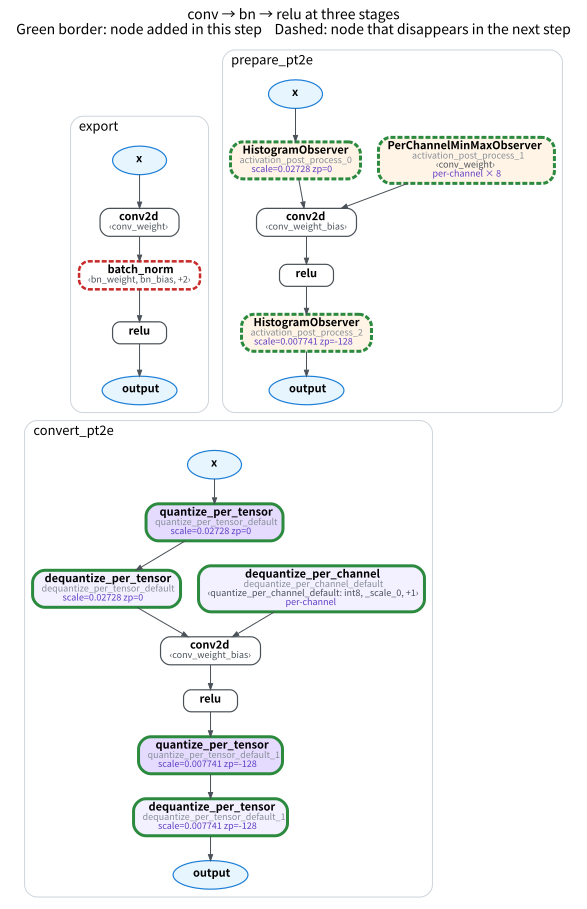

In [4]:
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
calibrate(prepared)
converted = convert_pt2e(copy.deepcopy(prepared))
draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")], title="conv → bn → relu at three stages")

In [5]:
def has_bn(g):
    return any("batch_norm" in str(n.target) for n in g.graph.nodes)


print("batch_norm in the graph? export:", has_bn(gm), " prepare:", has_bn(prepared), " convert:", has_bn(converted))
assert has_bn(gm) and not has_bn(prepared) and not has_bn(converted)

batch_norm in the graph? export: True  prepare: False  convert: False


- `batch_norm` is still there at export and is gone after `prepare_pt2e`; convert no longer touches BN.
- There is no "fused module" in the graph: `conv2d` and `relu` are still two separate nodes.

Before calling the Quantizer, `prepare_pt2e` folds the BN into the preceding conv (the M03 overview listed its steps), so the graph the Quantizer sees already has no BN.

## B. The Folding Itself Is Lossless

Prepare a fresh copy without calibrating: observers only observe and do not change values, so this graph is equivalent to the "fp32 graph with only BN folded". Compare with the original model:

In [6]:
fresh = prepare_pt2e(copy.deepcopy(gm), quantizer)
x = torch.randn(8, 3, 16, 16)
with torch.no_grad():
    diff = float((model(x) - fresh(x)).abs().max())
print(f"original model (conv + bn + relu) vs graph with BN folded: max|diff| = {diff:.2e}")
assert diff < 1e-5

original model (conv + bn + relu) vs graph with BN folded: max|diff| = 4.77e-07


The difference is only at the floating-point error scale: folding is just an algebraic rearrangement; all quantization error is added later.

## C. How the Weight Is Rewritten

An eval-mode BN applies $\mathrm{BN}(y) = \gamma \dfrac{y - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta$ to each channel,
where $\mu$, $\sigma^2$ are the running mean/var and $\gamma$, $\beta$ are the BN's weight/bias.
Substituting the conv output $y = W * x + b$ and rearranging gives another conv:

$$
W_{\text{fold}} = W \cdot \frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{1}
$$

$$
b_{\text{fold}} = \beta + (b - \mu)\,\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{2}
$$

The multiplication in Eq. (1) is per output channel: all weights of the $k$-th output channel are multiplied by the same $\gamma_k / \sqrt{\sigma_k^2+\varepsilon}$.
The conv in this model has no bias, so $b = 0$. First look at which parameters (`get_attr` nodes) the graph uses before and after prepare:

In [7]:
print("export:  ", [n.target for n in gm.graph.nodes if n.op == "get_attr"])
print("prepare:", [n.target for n in prepared.graph.nodes if n.op == "get_attr"])

export:   ['conv.weight', 'bn.weight', 'bn.bias', 'bn.running_mean', 'bn.running_var', 'bn.num_batches_tracked']
prepare: ['conv.weight', 'conv.weight_bias']


All four BN parameters are gone, and there is a new `conv.weight_bias`: the conv originally had no bias, but after folding it needs the bias of Eq. (2), so this new constant appears.
The name `conv.weight` is unchanged, but its value has become Eq. (1). Computing by hand with the BN parameters and comparing with what torchao folds:

In [8]:
bn = model.bn
assert bn.running_mean is not None and bn.running_var is not None
k = bn.weight / torch.sqrt(bn.running_var + bn.eps)  # one γ/√(σ²+ε) per output channel
w_fold = model.conv.weight * k.reshape(-1, 1, 1, 1)  # Eq. (1)
b_fold = bn.bias - bn.running_mean * k  # Eq. (2), b = 0

w_torchao = prepared.get_parameter("conv.weight")
b_torchao = getattr(prepared.get_submodule("conv"), "weight_bias")  # the bias newly added when folding BN
print(f"how much the weight was rewritten: max|W_fold - W| = {float((w_torchao - model.conv.weight).abs().max()):.3f}")
print("Eq. (1) matches torchao's weight?", torch.allclose(w_torchao, w_fold, atol=1e-6))
print("Eq. (2) matches torchao's bias?  ", torch.allclose(b_torchao, b_fold, atol=1e-6))
assert torch.allclose(w_torchao, w_fold, atol=1e-6) and torch.allclose(b_torchao, b_fold, atol=1e-6)

how much the weight was rewritten: max|W_fold - W| = 0.016
Eq. (1) matches torchao's weight? True
Eq. (2) matches torchao's bias?   True


So the weight quantized after prepare is already the weight of conv and BN combined, not the original `conv.weight`.

Each output channel is multiplied by a different $\gamma_k / \sqrt{\sigma_k^2+\varepsilon}$, so after folding the value ranges of the channels differ in size.
Inference (the error gap is not measured here): this is one of the reasons per-channel weight quantization matters especially for models with BN.

QAT cannot fold like this at prepare time, because during training BN still needs batch statistics; see M04-2.

## D. After Folding: The Quantization Point Between conv and relu

Once BN is folded, conv_bn_relu looks the same as conv_relu in the graph. With XNNPACKQuantizer, compare between which two nodes the activation observers of the two models sit:

In [9]:
def activation_sites(prepared):
    """Write each activation observer as "upstream → downstream"; skip weight observers (whose input is get_attr)."""
    return [f"{n.args[0].name} → {', '.join(u.name for u in n.users)}"
            for n, _ in observer_nodes(prepared) if n.args[0].op != "get_attr"]


sites = {}
for name in ("conv_relu", "conv_bn_relu"):
    p = prepare_pt2e(export_module(get_model(name).eval(), example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
    sites[name] = activation_sites(p)
    print(f"{name:<13}", sites[name])
assert sites["conv_relu"] == sites["conv_bn_relu"]

conv_relu     ['x → conv2d', 'relu → output']


conv_bn_relu  ['x → conv2d', 'relu → output']


The two are identical: one at the input and one at the relu output, none between conv and relu. This is the result of XNNPACKQuantizer putting the output annotation on relu, not on conv (M03-2 A),
which is PT2E's "fusion" of conv + relu.

In M03-3 and M03-6 we saw on the prepared graph that "annotating the conv's output too" adds an observer. Here we look at what it looks like **after convert**.
The two Quantizers differ in only one thing: with `fuse=False`, the conv's output is annotated too.

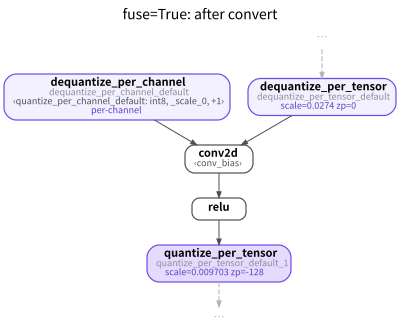

In [10]:
class ConvReluQuantizer(Quantizer):
    def __init__(self, fuse: bool):
        self.fuse = fuse

    def annotate(self, model):
        for conv in [n for n in model.graph.nodes if n.op == "call_function" and n.target == CONV2D]:
            annotate_input_qspec_map(conv, conv.args[0], act_spec())
            annotate_input_qspec_map(conv, conv.args[1], weight_spec())
            relu = next(u for u in conv.users if u.target == RELU)
            annotate_output_qspec(relu, act_spec())
            if not self.fuse:
                annotate_output_qspec(conv, act_spec())  # one extra annotation: the conv output is quantized too
            for node in (conv, relu):
                node.meta[ANNOTATION_KEY]._annotated = True
        return model

    def validate(self, model):
        pass


gm_cr = export_module(get_model("conv_relu").eval(), example_inputs())
results = {}
for fuse in (True, False):
    p = prepare_pt2e(copy.deepcopy(gm_cr), ConvReluQuantizer(fuse))
    calibrate(p)
    results[fuse] = convert_pt2e(p)
draw(results[True], focus=["conv2d", "relu"], title="fuse=True: after convert")

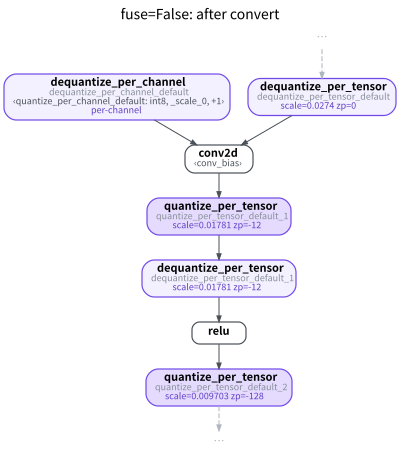

In [11]:
draw(results[False], focus=["conv2d", "relu"], title="fuse=False: after convert")

In [12]:
def between_conv_and_relu(g):
    """Walk back from the relu input to the conv and return the nodes passed through."""
    relu = next(n for n in g.graph.nodes if n.target == RELU)
    steps, src = [], relu.args[0]
    while src.target != CONV2D:
        steps.append(str(src.target).split(".")[1])
        src = src.args[0]
    return steps[::-1]


print("fuse=True:  between conv2d and relu:", between_conv_and_relu(results[True]))
print("fuse=False: between conv2d and relu:", between_conv_and_relu(results[False]))
assert between_conv_and_relu(results[True]) == []
assert between_conv_and_relu(results[False]) == ["quantize_per_tensor", "dequantize_per_tensor"]

fuse=True:  between conv2d and relu: []
fuse=False: between conv2d and relu: ['quantize_per_tensor', 'dequantize_per_tensor']


- **fuse=True**: conv2d connects directly to relu, with an fp32 tensor in between. The whole thing is dq → conv2d → relu → q.
- **fuse=False**: a quantize → dequantize pair is inserted between conv2d and relu, giving dq → conv2d → q → dq → relu → q.

As seen in M02-3 C, backend lowering matches patterns like "dq → op → q" on the Q/DQ graph and then replaces them with integer kernels.
A conv + relu kernel requires conv and relu to be adjacent; with a q/dq pair between them, it can only be split into two kernels, conv and relu, and the conv output is first stored as int8 and then read back.
Inference (no per-kernel comparison here): an extra quantization point also means an extra rounding, and the conv output range includes the negative values that relu will clip, wasting part of the integer range.

## Summary

- PTQ's BN is folded into the conv right at the start of `prepare_pt2e`, before the Quantizer's `annotate`; the folding is lossless.
- The folded weight is Eq. (1) and the bias is Eq. (2); a conv that originally had no bias grows a `weight_bias`.
- PT2E's "fusion" = BN folding + no quantization point between conv and relu; add one and convert leaves an extra q/dq pair, so the backend's pattern no longer matches.